# Module 8. Neural Networks and Deep Learning

## 8.1 - Project: Fashion Classification

### From tables (structured) to images (unstructured)

In all previous modules, we worked with tabular data (CSVs with rows and columns). Linear regression, logistic regression and tree-based models are all made for data like this.

This week the data is different. Instead of a table, we have images - pictures of clothes. Given a picture, we want to predict what kind of clothing it shows.

The project is multi-class classification. We build a model that tells whether an image belongs to one of 10 clothing categories.

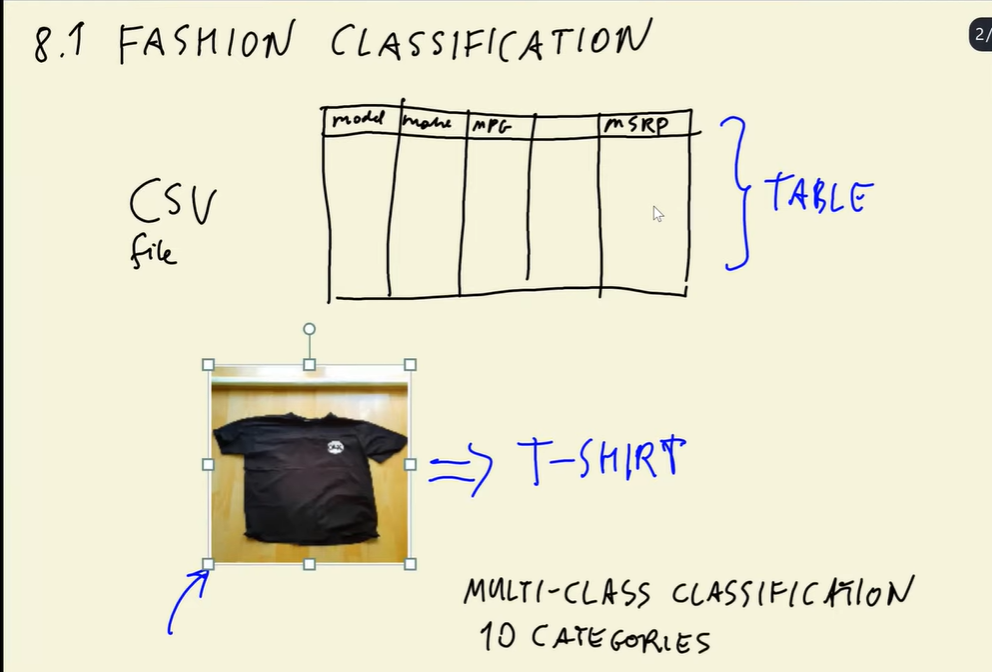

### Use case

An online marketplace website, the kind where people sell things. A user wants to sell a t-shirt, so they create a listing in the fashion category and upload a picture of it.

On the backend we have a fashion classification service. It takes the picture and replies with a suggested category - in this case "t-shirt". The user sees the suggestion, clicks publish, and the listing is done. Uploading a picture and clicking publish is much simpler than picking a category by hand, so this helps users create listings faster.

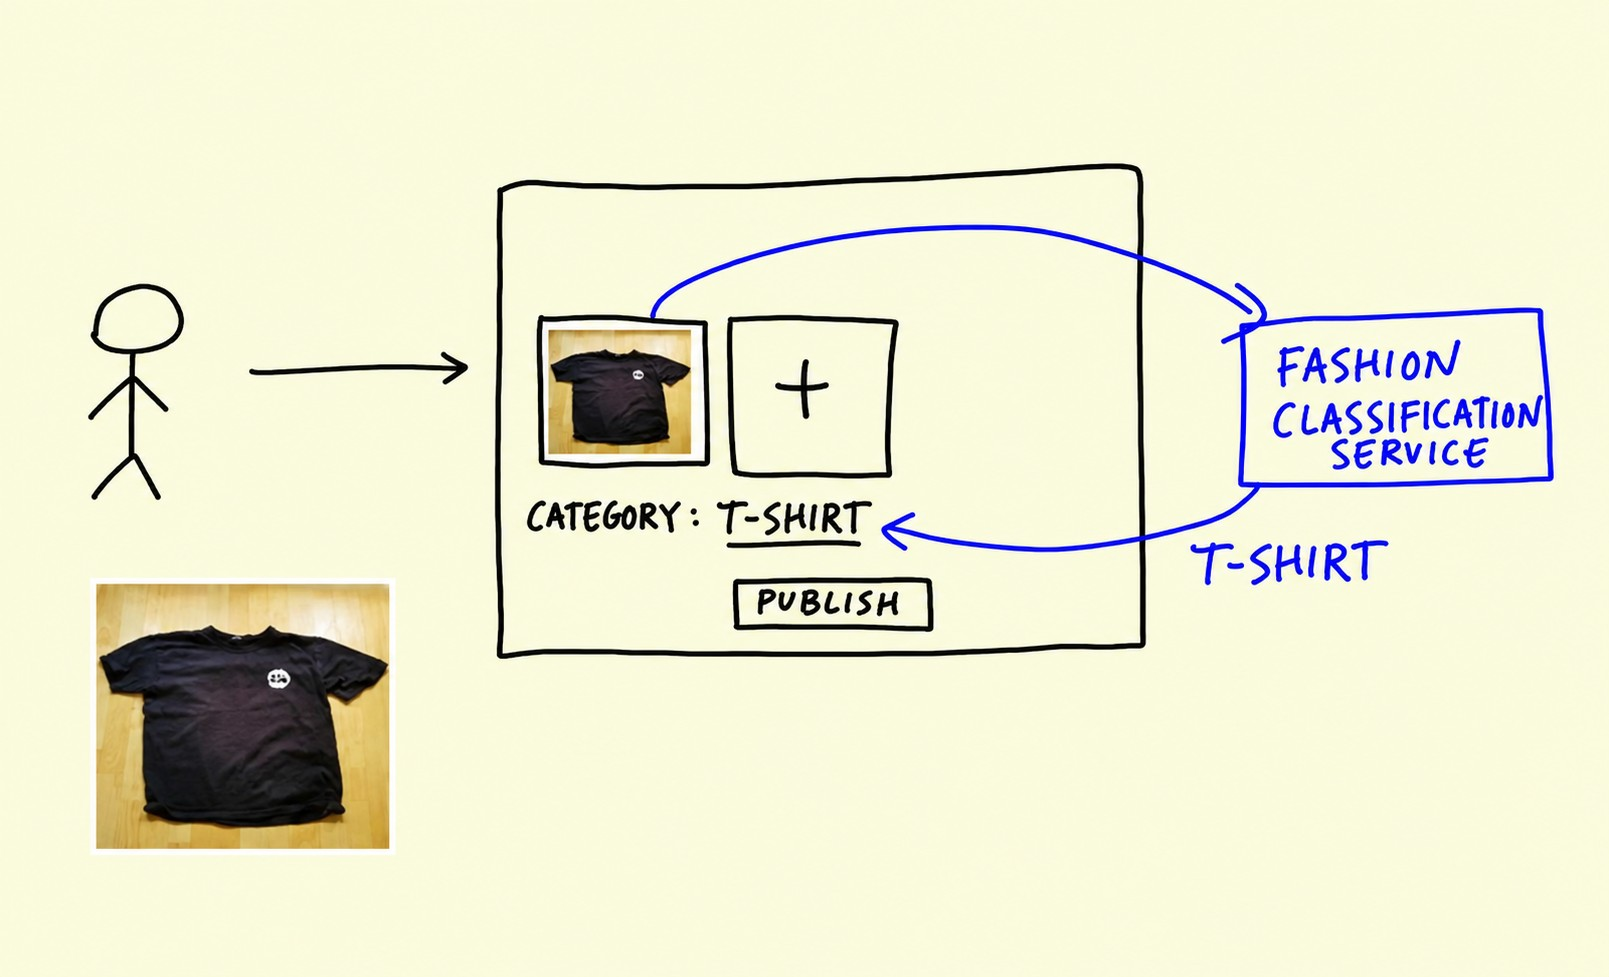

### Dataset

Clone this repo:
https://github.com/alexeygrigorev/clothing-dataset-small

## 8.2 - Tensorflow and Keras

### What is Tensorflow and Keras?

TensorFlow is a library from Google for doing deep learning. Its an end-to-end open source machine learning platform - it can do other things, but the main focus is deep learning. For us, TensorFlow is a library for training deep learning models.

Keras is a higher-level abstraction on top of TensorFlow. It makes it simpler to create, train and use neural networks. Keras lives inside TensorFlow. Keras used to be a separate library, but it got absorbed into TensorFlow. Since TensorFlow 2.0 it is a part of TensorFlow - so make sure you use TensorFlow 2.0 or above.

### Install TensorFlow + Keras (GPU)

```bash
uv add "tensorflow[and-cuda]"   # Keras is included
```

Check the GPU is detected:

```python
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))  # [] means CPU only
```


In [1]:
import numpy as np
import matplotlib.pyplot as plt

import ctypes, os, nvidia.cusolver
# TF 2.21 can't find cuSOLVER on its own, so load it first
ctypes.CDLL(os.path.join(nvidia.cusolver.__path__[0], 'lib', 'libcusolver.so.11'))

# hide TF info messages
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'  

import tensorflow as tf

import tensorflow as tf
from tensorflow import keras


print(f"TensorFlow version: {tf.__version__}")
print(f"Keras version: {keras.__version__}")
print(tf.config.list_physical_devices('GPU'))  # should list one GPU


I0000 00:00:1795312440.959340   16892 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795312444.996853   16892 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0
Keras version: 3.15.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Loading image data

Neural networks expect every input to have the same shape, so all images get resized to one size. Xception was trained on 299×299 images, so that's the size it expects.

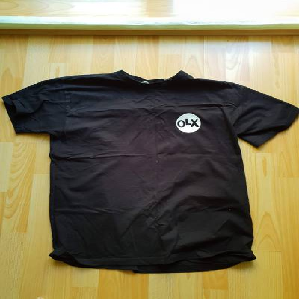

In [2]:
from tensorflow.keras.preprocessing.image import load_img


path = './clothing-dataset-small/train/t-shirt'
name = '5f0a3fa0-6a3d-4b68-b213-72766a643de7.jpg'
fullname = f'{path}/{name}'

img = load_img(fullname, target_size=(299, 299))
img

In [3]:
type(img)

PIL.Image.Image

### How an image is stored

A color image is 3 grids of numbers called **channels**: Red, Green and Blue.

- Shape is `(height, width, channels)`, e.g. `(150, 150, 3)`.
- Each pixel has 3 values `(R, G, B)`, one from each channel.
- Each value is 0–255 (1 byte). 0 means none of that color, and 255 means full. A black pixel is `(0, 0, 0)`.


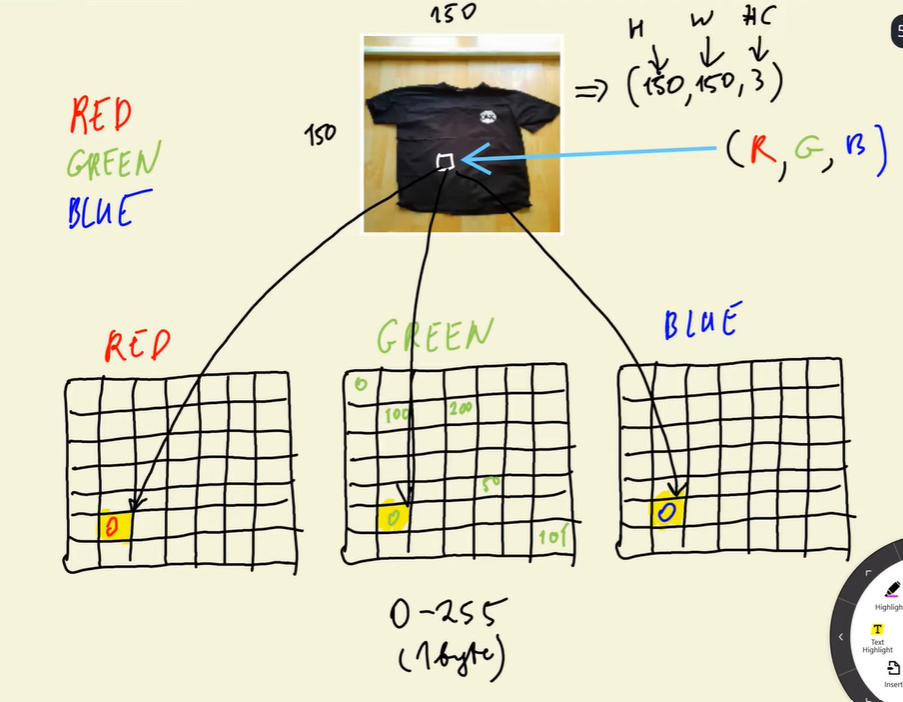

### Convert PIL image to NumPy array

In [4]:
img_array = np.array(img)
img_array

array([[[179, 171,  99],
        [179, 171,  99],
        [181, 173, 101],
        ...,
        [251, 253, 248],
        [251, 253, 248],
        [251, 254, 247]],

       [[188, 179, 112],
        [187, 178, 111],
        [186, 177, 108],
        ...,
        [251, 252, 247],
        [251, 252, 247],
        [251, 252, 246]],

       [[199, 189, 127],
        [200, 190, 128],
        [200, 191, 126],
        ...,
        [250, 251, 245],
        [250, 251, 245],
        [250, 251, 245]],

       ...,

       [[165, 151,  76],
        [173, 159,  84],
        [171, 157,  82],
        ...,
        [183, 135,  25],
        [181, 133,  22],
        [183, 135,  24]],

       [[165, 151,  76],
        [173, 159,  84],
        [171, 157,  82],
        ...,
        [182, 134,  23],
        [180, 132,  21],
        [182, 134,  23]],

       [[165, 151,  76],
        [173, 159,  84],
        [171, 157,  82],
        ...,
        [181, 133,  22],
        [179, 131,  20],
        [182, 134,  23]]

In [5]:
img_array.shape

(299, 299, 3)

## 8.3 - Pre-Trained Convolutional Neural Networks

### Xception

In [6]:
from tensorflow.keras.applications.xception import Xception
from tensorflow.keras.applications.xception import preprocess_input
from tensorflow.keras.applications.xception import decode_predictions

In [7]:
model = Xception(weights='imagenet', input_shape=(299, 299, 3))

The first parameter, `weights='imagenet'`, means we want the network that was pre-trained on ImageNet. 

The input to this model is `299x299x3`

### Preprocessing

The model doesn't expect just one image - it expects a bunch of images. So we create a NumPy array with our image inside:

In [8]:
X = np.array([img])
X.shape

(1, 299, 299, 3)

The shape is `(1, 299, 299, 3)`: one image, 299 by 299, with three channels. 

If we had several images - say 3 - we would put all of them in this array, and the shape would be `(3, 299, 299, 3)`:

In [9]:
X

array([[[[179, 171,  99],
         [179, 171,  99],
         [181, 173, 101],
         ...,
         [251, 253, 248],
         [251, 253, 248],
         [251, 254, 247]],

        [[188, 179, 112],
         [187, 178, 111],
         [186, 177, 108],
         ...,
         [251, 252, 247],
         [251, 252, 247],
         [251, 252, 246]],

        [[199, 189, 127],
         [200, 190, 128],
         [200, 191, 126],
         ...,
         [250, 251, 245],
         [250, 251, 245],
         [250, 251, 245]],

        ...,

        [[165, 151,  76],
         [173, 159,  84],
         [171, 157,  82],
         ...,
         [183, 135,  25],
         [181, 133,  22],
         [183, 135,  24]],

        [[165, 151,  76],
         [173, 159,  84],
         [171, 157,  82],
         ...,
         [182, 134,  23],
         [180, 132,  21],
         [182, 134,  23]],

        [[165, 151,  76],
         [173, 159,  84],
         [171, 157,  82],
         ...,
         [181, 133,  22],
        

Xception model expects the input to look a certain way. When it was trained, all the images were preprocessed with a special function, so we have to apply exactly the same function to our data:

In [10]:
X = preprocess_input(X)
X

array([[[[ 0.4039216 ,  0.3411765 , -0.2235294 ],
         [ 0.4039216 ,  0.3411765 , -0.2235294 ],
         [ 0.41960788,  0.35686278, -0.20784312],
         ...,
         [ 0.96862745,  0.9843137 ,  0.94509804],
         [ 0.96862745,  0.9843137 ,  0.94509804],
         [ 0.96862745,  0.99215686,  0.9372549 ]],

        [[ 0.47450984,  0.4039216 , -0.12156862],
         [ 0.4666667 ,  0.39607847, -0.12941176],
         [ 0.45882356,  0.38823533, -0.15294117],
         ...,
         [ 0.96862745,  0.9764706 ,  0.9372549 ],
         [ 0.96862745,  0.9764706 ,  0.9372549 ],
         [ 0.96862745,  0.9764706 ,  0.92941177]],

        [[ 0.56078434,  0.48235297, -0.00392157],
         [ 0.5686275 ,  0.4901961 ,  0.00392163],
         [ 0.5686275 ,  0.49803925, -0.01176471],
         ...,
         [ 0.9607843 ,  0.96862745,  0.92156863],
         [ 0.9607843 ,  0.96862745,  0.92156863],
         [ 0.9607843 ,  0.96862745,  0.92156863]],

        ...,

        [[ 0.2941177 ,  0.18431377, -0

After preprocessing, our image no longer contains numbers between 0 and 255 - they are converted to numbers between -1 and 1:

We have to do this if we want the model to function correctly, because this is the preprocessing that was used for training it.

### Making a prediction

In [11]:
pred = model.predict(X)
pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step


array([[3.23752844e-04, 1.57284099e-04, 2.13412437e-04, 1.52314766e-04,
        2.47616699e-04, 3.04813962e-04, 3.20447958e-04, 1.47512284e-04,
        2.03556090e-04, 1.49324856e-04, 1.95593748e-04, 2.10029451e-04,
        7.58943061e-05, 1.13950839e-04, 1.62592070e-04, 2.04540920e-04,
        1.97295783e-04, 1.44222475e-04, 1.40111413e-04, 1.73622102e-04,
        7.46231352e-04, 2.56716768e-04, 2.66776362e-04, 2.96390906e-04,
        3.73363640e-04, 2.77294283e-04, 2.16454646e-04, 2.27214288e-04,
        3.80778569e-04, 1.72055064e-04, 3.05401976e-04, 1.96392823e-04,
        3.92062939e-04, 4.77958092e-04, 2.91530305e-04, 3.25640664e-04,
        1.47359300e-04, 1.62333017e-04, 2.12616113e-04, 1.34011949e-04,
        2.39986781e-04, 6.75094896e-04, 2.54898914e-04, 1.44487771e-04,
        4.12816968e-04, 2.04301730e-04, 3.02910339e-04, 1.49284577e-04,
        1.99575166e-04, 2.26974094e-04, 2.93650111e-04, 2.27366661e-04,
        6.37614517e-04, 7.82366027e-04, 2.49560224e-04, 4.050967

In [12]:
pred.shape

(1, 1000)

The shape is (1, 1000) - 1000 classes, one image. Each value in this array is the probability that our image belongs to that class.



### Decoding the prediction

To make sense of this output we need to know which class each of the 1000 values corresponds to. There is another function in the Xception package - decode_predictions. It looks at the predictions and makes them human-readable, downloading the mapping from indices to class names:

In [13]:
decode_predictions(pred)

[[('n03595614', 'jersey', np.float32(0.6821469)),
  ('n02916936', 'bulletproof_vest', np.float32(0.03805238)),
  ('n04370456', 'sweatshirt', np.float32(0.034298327)),
  ('n03710637', 'maillot', np.float32(0.011359448)),
  ('n04525038', 'velvet', np.float32(0.0018457203))]]

### Why it doesn't work for us

The top class is jersey with probability 0.68. It's not exactly a t-shirt - but it's also not very far. The other suggestions are a bulletproof vest, a sweatshirt, a maillot and velvet - related items, but not really what we need.

The reason is in the ImageNet classes themselves. If we look at the list, there are all sorts of things - but there's no t-shirt. There are sweatshirts, but no t-shirts and no simple shirts.

Even though ImageNet is big, comprehensive and general, when it comes to clothes and fashion it's not particularly good. So this model doesn't work for our purpose. Remember what we wanted: suggest a proper category to the users of our website when they create a listing. For that we need to train a different model, with the classes we need for our particular case.

The good news: we don't have to train from scratch. We can reuse these pre-trained models and build on top of what big companies and universities have already trained, adapting them to our use case.

## 8.4 - Convolutional Neural Networks

The model we used in the previous unit, Xception, is a convolutional neural network. In this unit we go inside it: what convolutional layers and dense layers are, how filters turn an image into a vector representation, and how that vector becomes a prediction.

### What is inside a CNN

Convolutional neural networks (CNNs) are the type of neural networks used mostly for images. They consist of different types of layers, and one of them is called a convolutional layer - that's where the name comes from.

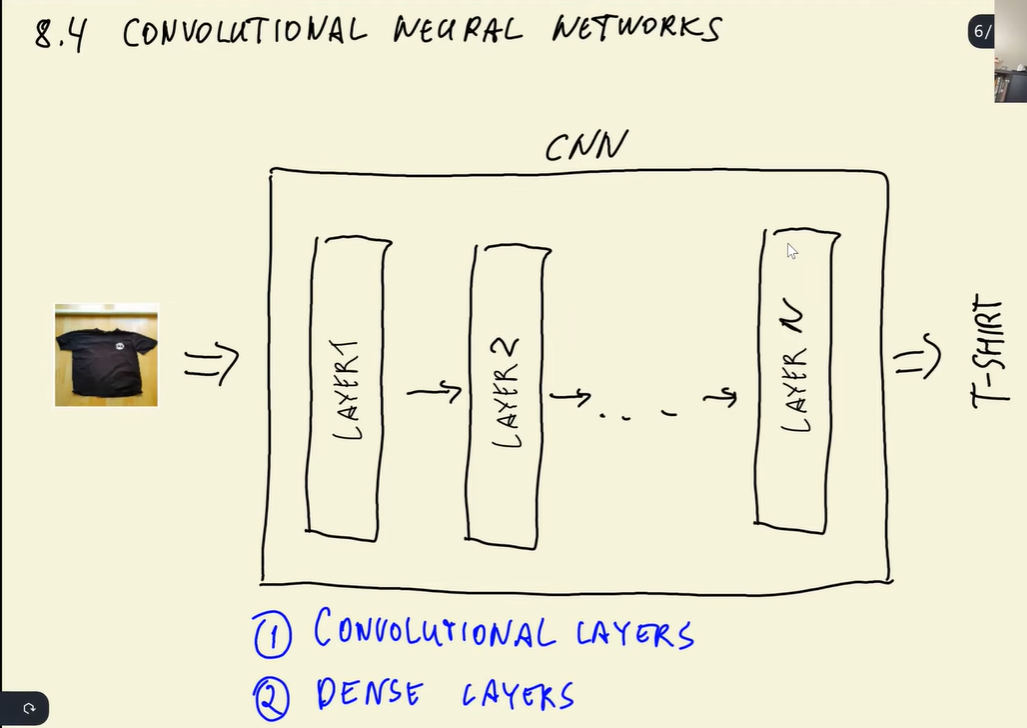

### Convolutional layers and filters

Convolutional layers consist of **filters**. A filter is kind of a small image (e.g. 5x5) and there are quite a few of them in a layer.

The filters contain simple shapes: lines, stripes, circles (this is just an example, not a real network).

We take our image, take a filter, and *slide this filter across the image*. Every time we apply the filter, we check how similar the filter is to the part of the image it currently covers. The similarity is a number: zero usually means no similarity, a higher number means bigger similarity.

We record this number for each position of the filter. The resulting array is called a **feature map**.

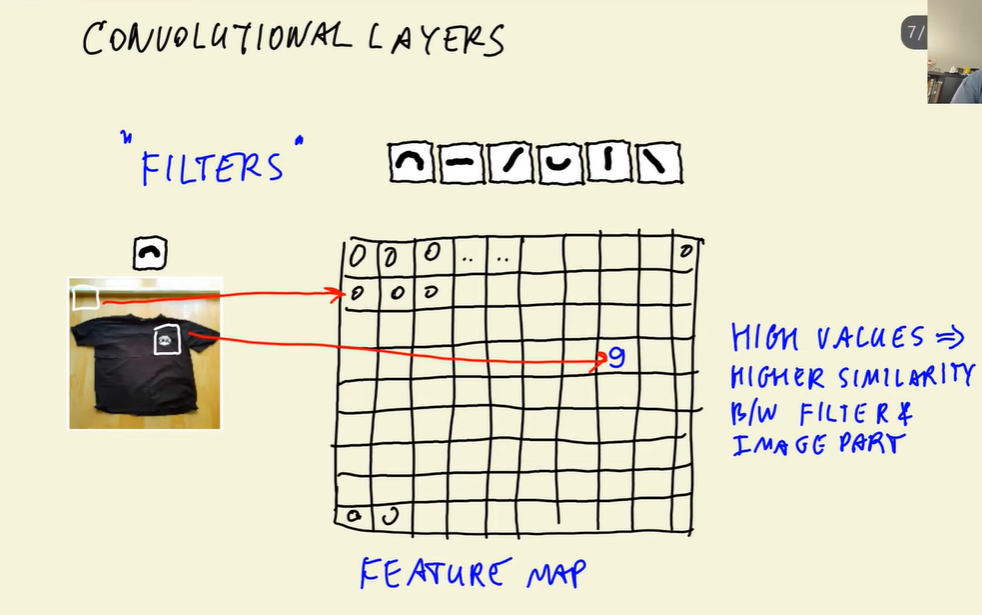

The feature map is the result of applying one filter to an image: we slide the filter across the image, compute the similarity at every position, and record it. High values mean the filter is similar to that part of the image.

We do this for each filter. If a convolutional layer has six filters, it produces six feature maps - one feature map per filter:

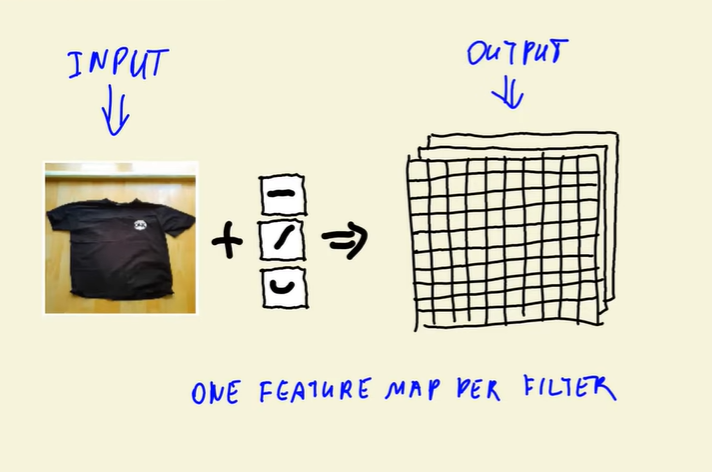

So the input of a convolutional layer is the image, and the output is a set of feature maps, as many as there are filters.

### Chaining convolutional layers

The output of the first convolutional layer is a set of feature maps. We can treat this output as a new image - an image that we made from the original one - and feed it to another convolutional layer. This layer has its own set of filters, applies them to the output of the first layer, and produces its own feature maps:

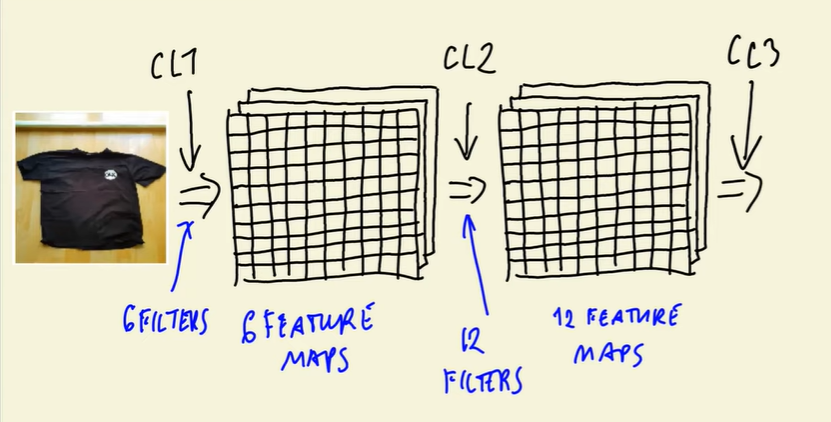

Because of this chaining, each layer learns more and more complex filters. **These filters are what a neural network learns during training**. 

The first convolutional layer typically learns simple filters - just stripes. The second layer combines the filters from the first layer: a circle can be a combination of two stripes, an angle can be two lines put together, a cross as well. By the third layer the shapes are even more complex.

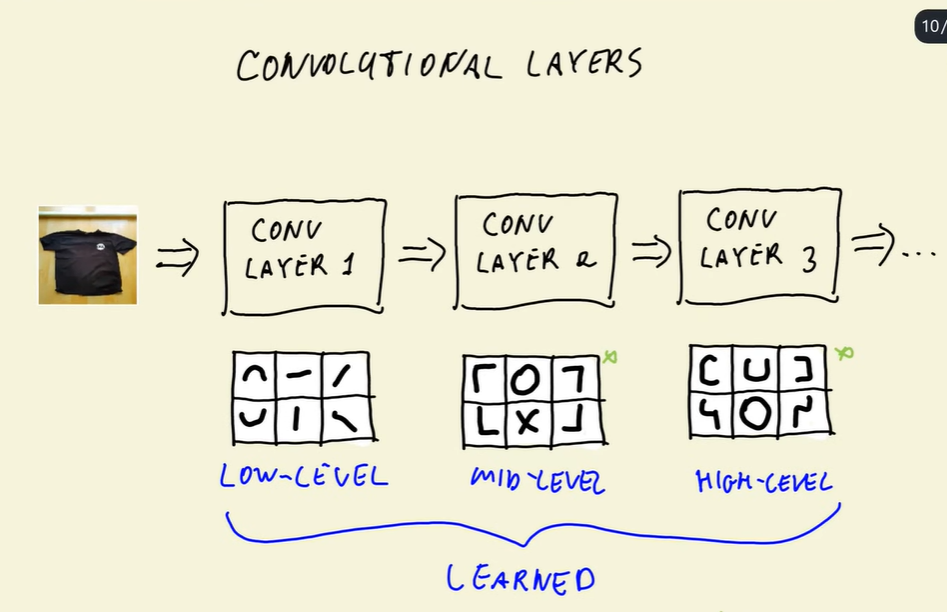

### Vector representation

We take our image and pass it through a set of convolutional layers. The result of this is a v**ector representation of the image**.

If the input image is 299x299x3, the vector representation could be something like 2048 numbers - a one-dimensional array. The dimensionality is usually 2048 or 1024 - *typically powers of two*.

**This vector captures the information about the image**. There could be an area that says there are sleeves, an area that corresponds to color, an area for some other part of the image, and so on. It's very hard for people to make sense of these numbers, but for neural networks they make sense, and they contain all the information the network was able to extract from the image.

So the **role of convolutional layers is to extract this vector representation**.

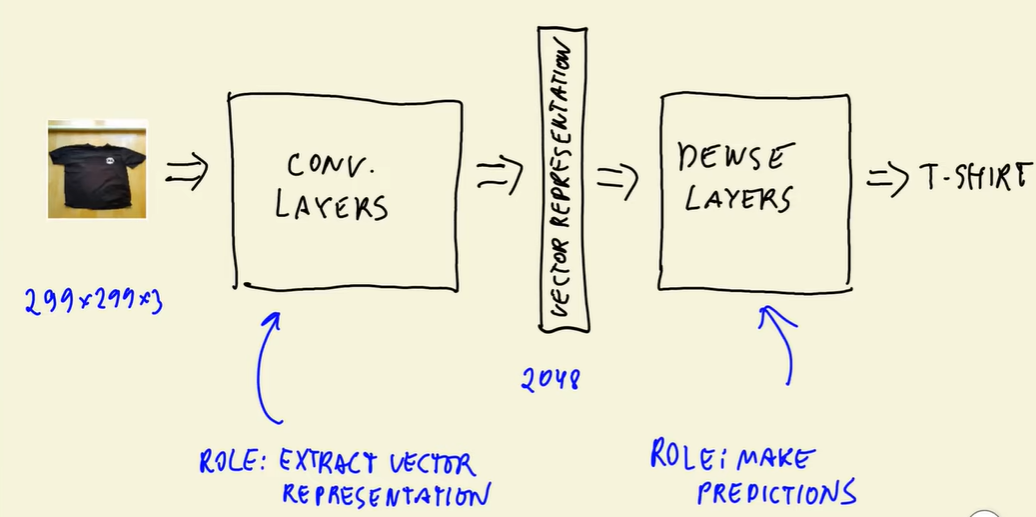

### Dense layers

With this vector we can build a model that makes the final prediction. 

Dense layers take the vector representation and turn it into predictions.

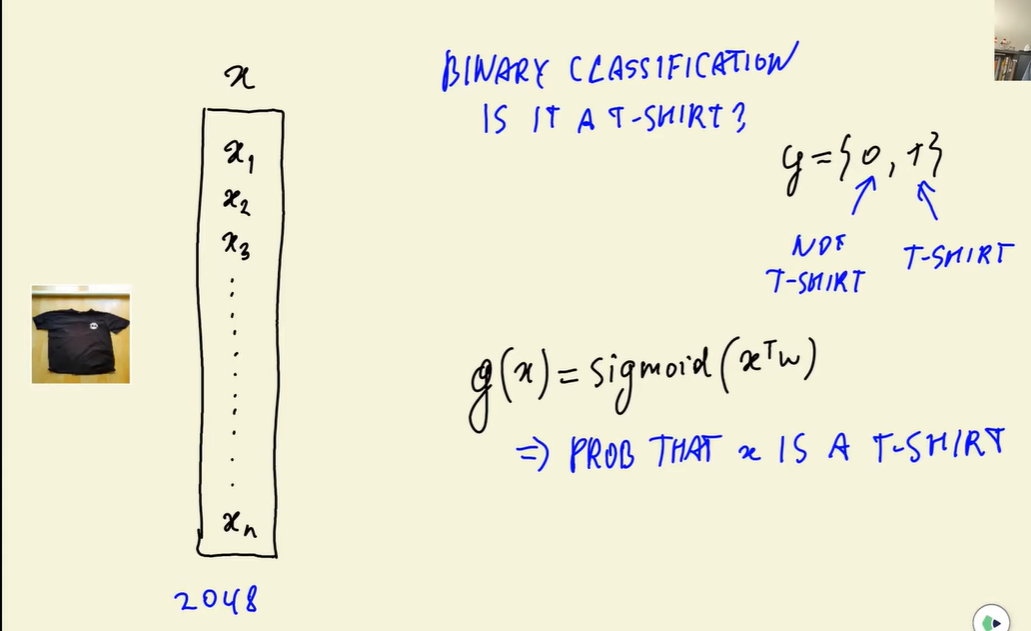

Let's start with binary classification: *is this a t-shirt, or not?* 

The input x is the vector representation of the image.

The target y is 0 (not a t-shirt) or 1 (t-shirt). 

For this we usually use logistic regression: g(x) is a sigmoid. 

The weights are trained, and the output is the probability that x is a t-shirt:

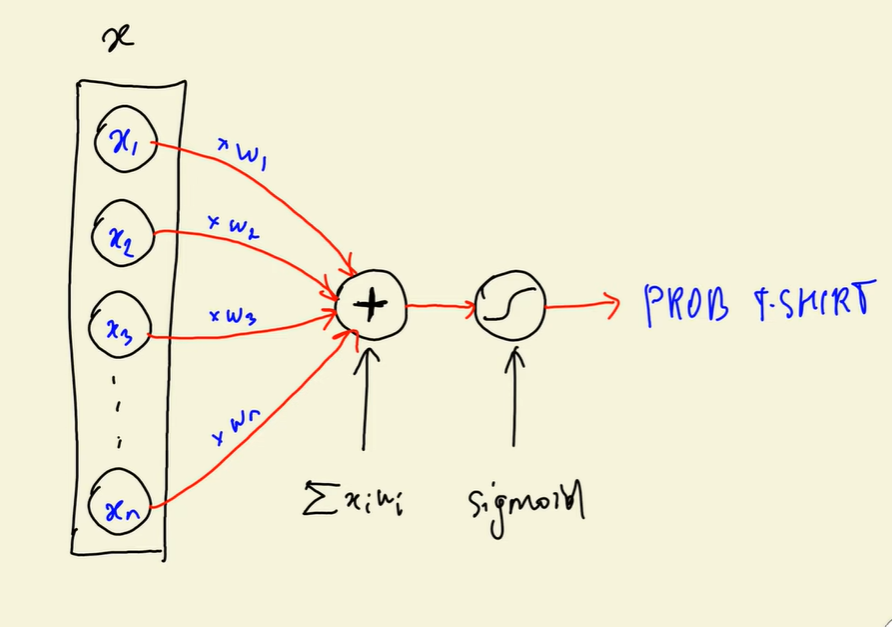

Now let's imagine we want multiple classes: in addition to t-shirt, a shirt and a dress. 

We can build three models, one per class. Each model gets the same input - the vector representation - but each has its own set of weights: red ones for t-shirts, green ones for shirts, blue ones for dresses.

nstead of sigmoid, for multiple classes we use **softmax** - it's a generalization of sigmoid to multiple classes. The output is a three-dimensional vector: the first component is the probability of shirt, the second of t-shirt, the third of dress.

What we have done here is put multiple logistic regressions together - and as a result we got a neural network.

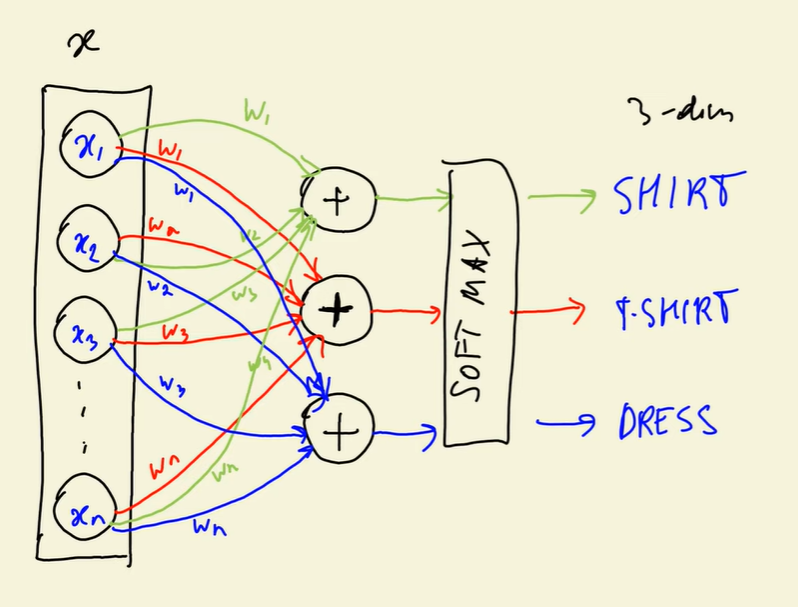

This layer is called a **dense layer**. The input to the layer is the vector representation, and the output is the predictions:

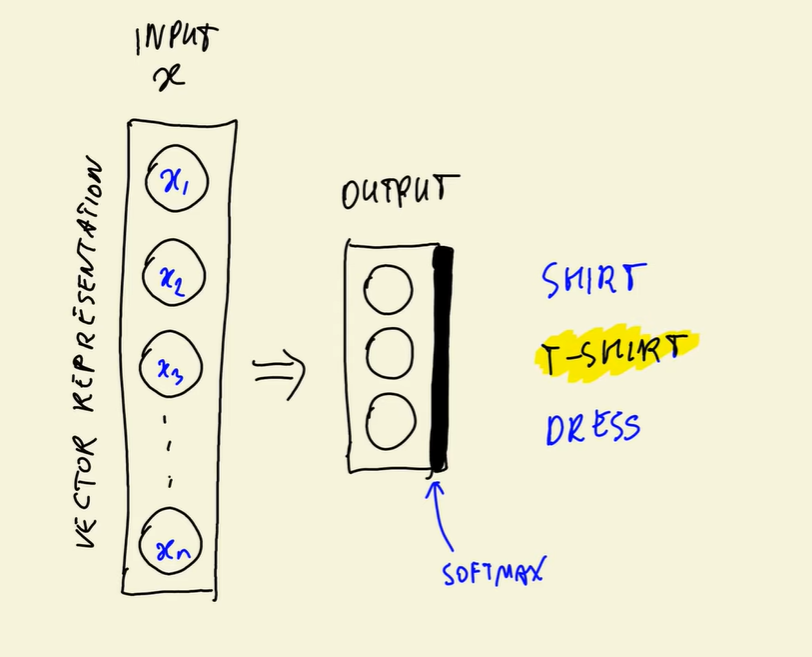

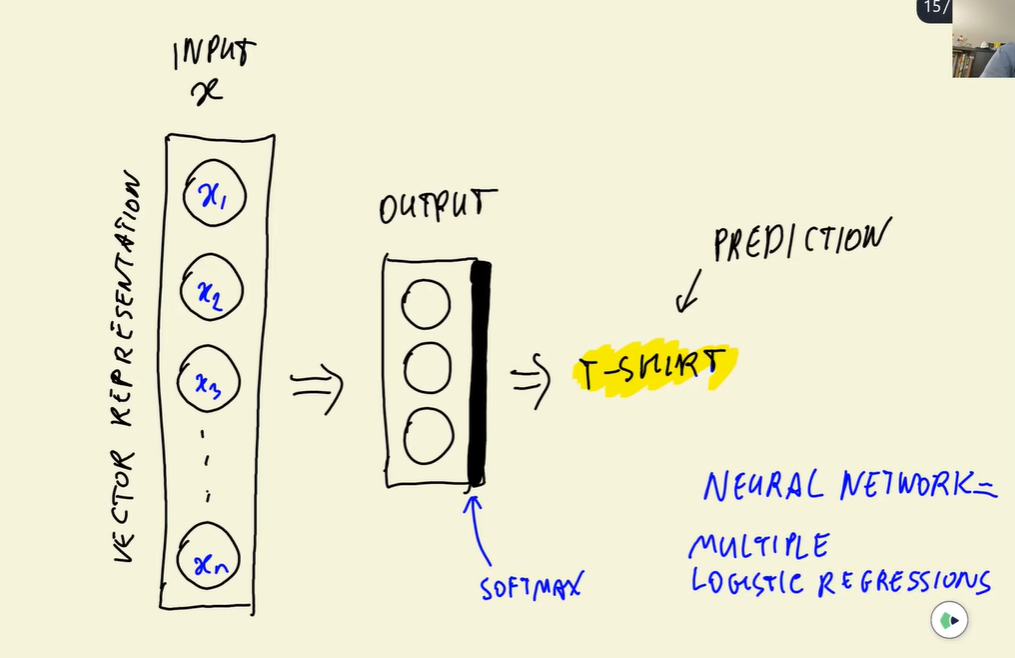

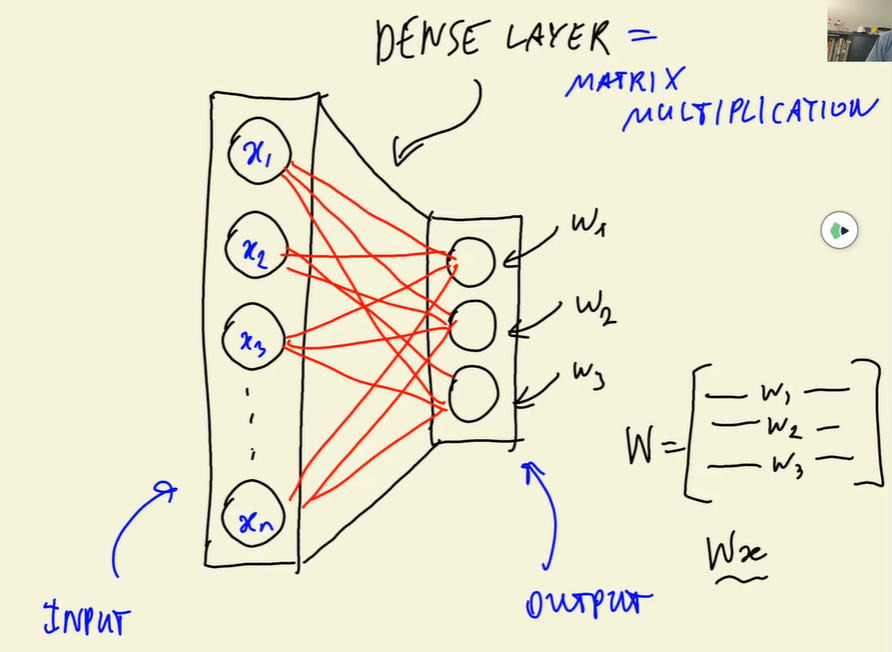

It's called *"dense"* because each element of the input is connected to each element of the output - there are a lot of connections, the area is really dense.

We can put multiple dense layers together. The layer between the input and the final predictions is called an inner dense layer, and the last one is the final dense layer for predictions:

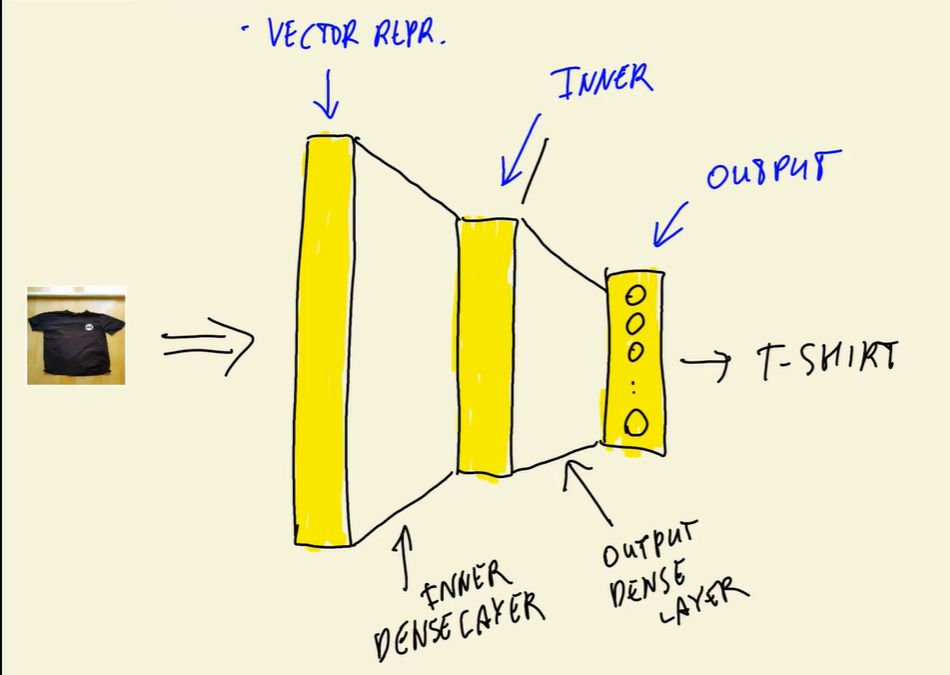

### Summary

For our clothing classifier: we take the image, turn it into a vector representation with convolutional layers, convert this vector into some inner representation with a dense layer, and then finally convert it to the output - 10 values, one per class. From this output we select the one with the highest value, and hopefully it's t-shirt:

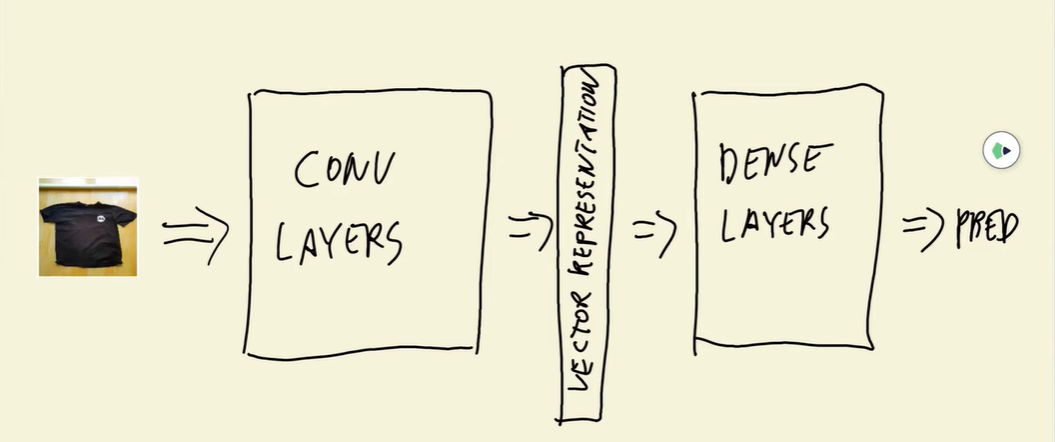

### Extra: Pooling layer

Makes a feature map smaller, so that they can take fewer parameters

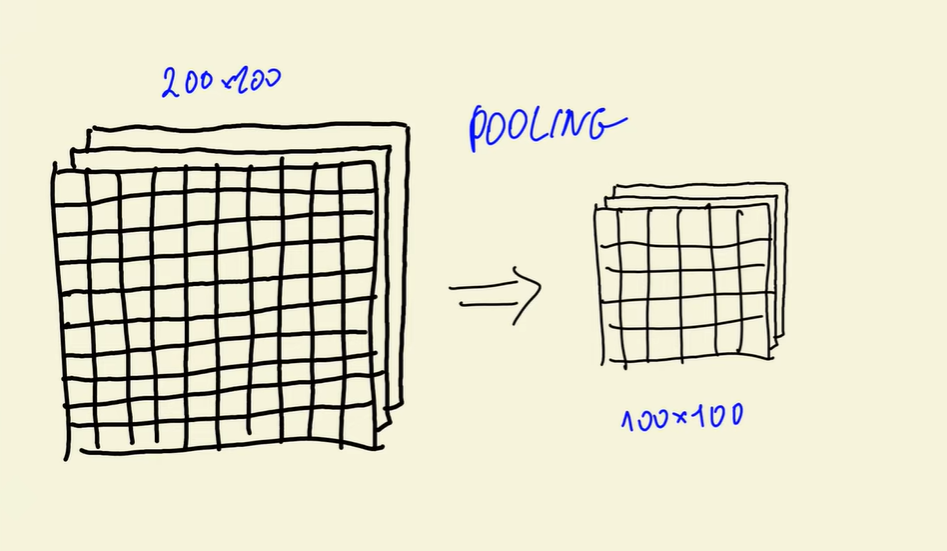

## 8.5 - Transfer Learning

### Concept

Remember that each convolutional layer of a neural network contains a bunch of filters. These filters are learnable - the model learns them during training - and the filters it learns are quite generic: they can be used for many purposes.

Somebody trained this model on the ImageNet dataset. Training these filters in the convolutional layers is very difficult: the model needs to see a huge amount of images to come up with filters that make sense. But once trained, the model can take any picture and convert it into a vector representation - and this is quite generic. We don't need to change it for our task.

The dense layers are a different story. They are specific to the dataset the model was trained on. ImageNet has 1000 different classes, so the output dense layer has a size of 1000. In our problem we want to predict only 10 classes - and many of them, like t-shirt, don't even exist in ImageNet.

So the plan is:

- Keep the convolutional layers - they already know how to turn an image into a vector representation.
- Throw away the dense layers from ImageNet and train our own dense layers for our 10 classes.

Everything the model learned previously - the most difficult part - is reused, and we transfer this knowledge to a new model. That's the main idea behind transfer learning.

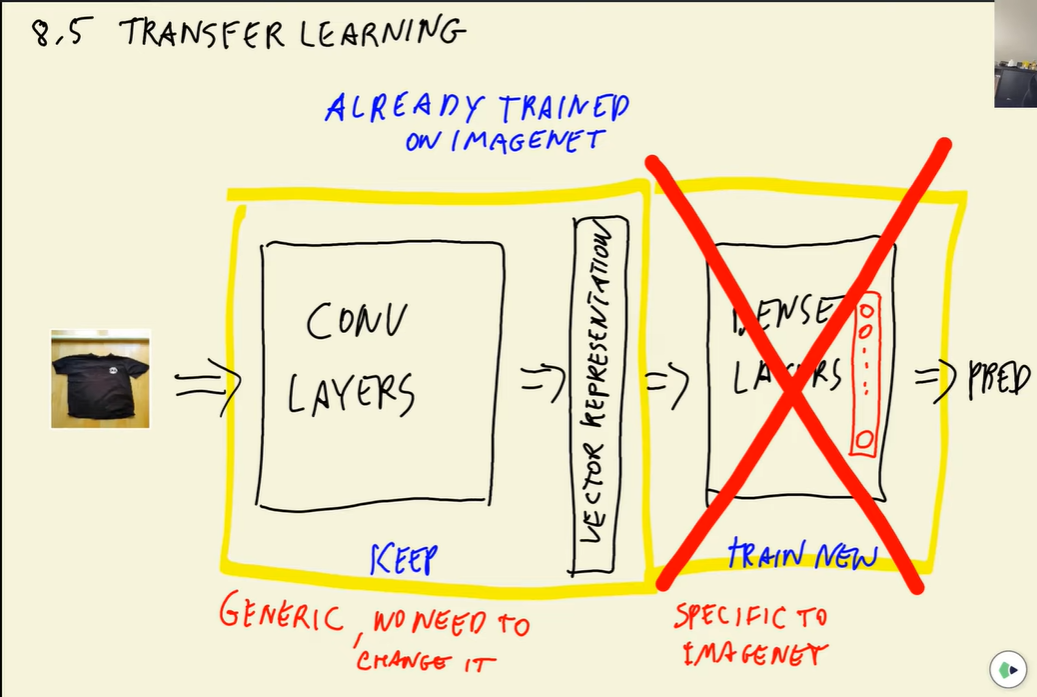

### Reading the data

In [14]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_ds = train_gen.flow_from_directory(
    './clothing-dataset-small/train',
    target_size=(150, 150),
    batch_size=32
)

Found 3068 images belonging to 10 classes.


In [15]:
train_ds.class_indices

{'dress': 0,
 'hat': 1,
 'longsleeve': 2,
 'outwear': 3,
 'pants': 4,
 'shirt': 5,
 'shoes': 6,
 'shorts': 7,
 'skirt': 8,
 't-shirt': 9}

The train dataset is a generator - an iterator. To get the next batch, we use the next function (a for loop invokes it internally):

In [16]:
X, y = next(train_ds)

In [17]:
X

array([[[[ 0.5686275 ,  0.43529415,  0.37254906],
         [ 0.45882356,  0.32549024,  0.26274514],
         [ 0.5058824 ,  0.37254906,  0.30980396],
         ...,
         [-0.14509803, -0.27058822, -0.3960784 ],
         [-0.2235294 , -0.40392154, -0.5294118 ],
         [-0.19999999, -0.41176468, -0.54509807]],

        [[ 0.60784316,  0.47450984,  0.41176474],
         [ 0.58431375,  0.45098042,  0.38823533],
         [ 0.4431373 ,  0.30980396,  0.24705887],
         ...,
         [-0.02745098, -0.12941176, -0.25490195],
         [-0.11372548, -0.26274508, -0.38039213],
         [-0.19999999, -0.38039213, -0.5058824 ]],

        [[ 0.56078434,  0.427451  ,  0.36470592],
         [ 0.427451  ,  0.2941177 ,  0.2313726 ],
         [ 0.54509807,  0.41176474,  0.34901965],
         ...,
         [-0.05098039, -0.15294117, -0.27843136],
         [ 0.05882359, -0.08235294, -0.19215685],
         [-0.01176471, -0.18431371, -0.27058822]],

        ...,

        [[ 0.41960788,  0.30196083,  0

In [18]:
y[:5]

array([[0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
       [0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0., 0., 0., 0., 0., 0.]], dtype=float32)

In [19]:
train_ds.class_indices

{'dress': 0,
 'hat': 1,
 'longsleeve': 2,
 'outwear': 3,
 'pants': 4,
 'shirt': 5,
 'shoes': 6,
 'shorts': 7,
 'skirt': 8,
 't-shirt': 9}

Now do the same thing for the validation set:

In [20]:
val_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

val_ds = val_gen.flow_from_directory(
    './clothing-dataset-small/validation',
    target_size=(150, 150),
    batch_size=32,
    shuffle=False
)

Found 341 images belonging to 10 classes.


### Building the model


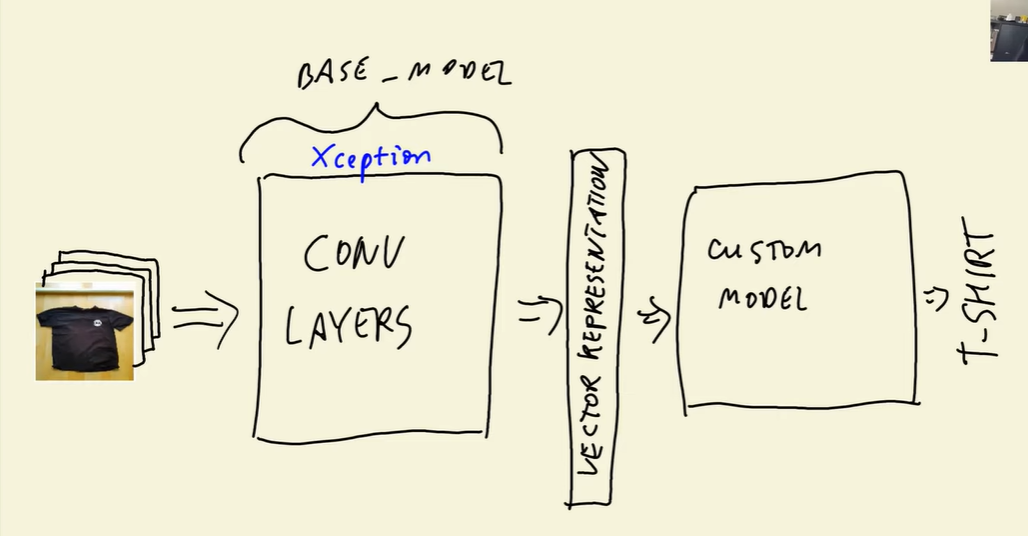

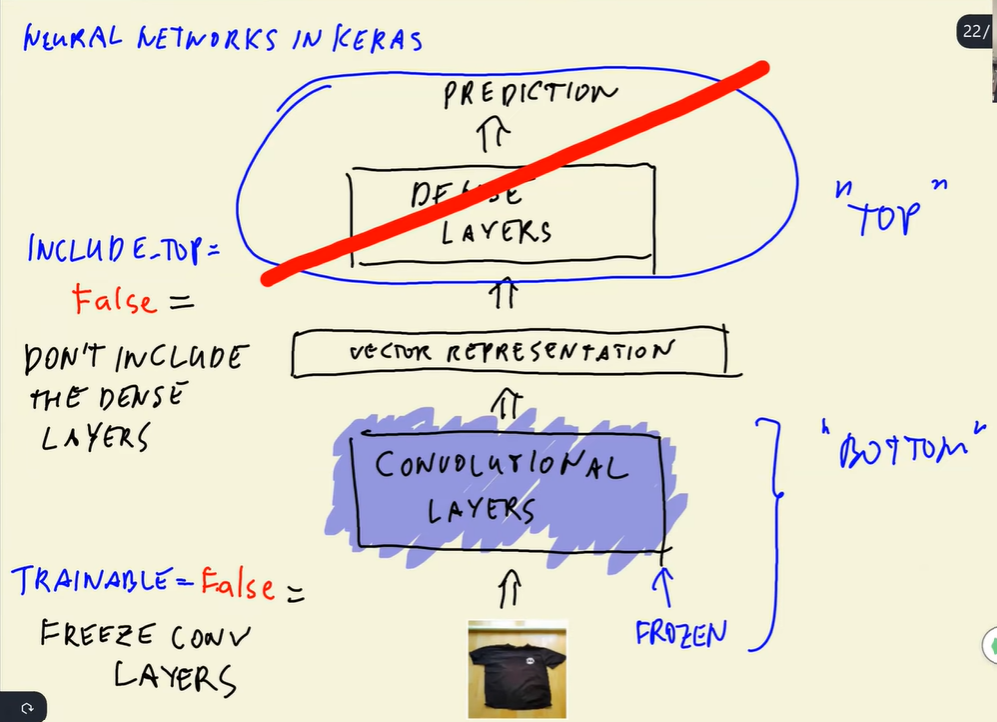

In [21]:
base_model = Xception(
    weights='imagenet',
    include_top=False,
    input_shape=(150, 150, 3)
)

base_model.trainable = False

83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 10s 0us/step


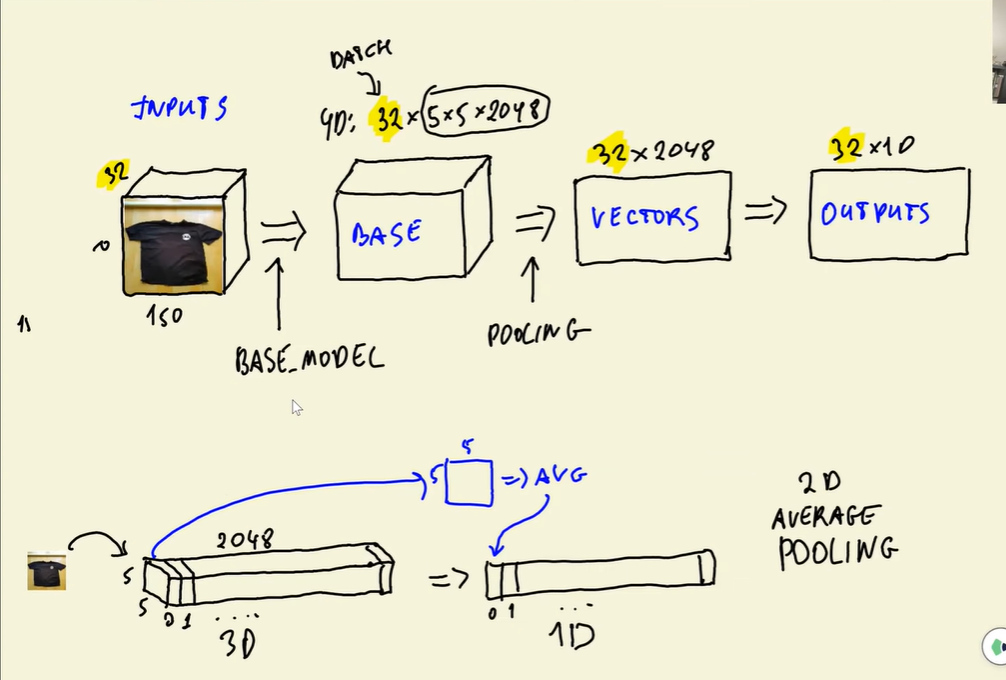

In [26]:
inputs = keras.Input(shape=(150, 150, 3))

base = base_model(inputs, training=False)

pooling = keras.layers.GlobalAveragePooling2D()
vectors = pooling(base)

dense = keras.layers.Dense(10)
outputs = dense(vectors)

model = keras.Model(inputs, outputs)

In [27]:
preds = model.predict(X)

preds.shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


(32, 10)

### Optimizer and loss

To train the model we need two things: an **optimizer** and a **loss**.

*The optimizer is the thing that finds the best weights for the model*. Remember the dense layer is a matrix W - training means changing each element of this matrix and checking whether the solution gets better, many many times. The optimizer does that. It doesn't change the weights randomly - it tries to change them in such a way that the model actually learns something.

In practice **Adam** is currently recommended as the default algorithm. So usually the recommendation is just to go with Adam.

In [28]:
learning_rate = 0.01
optimizer = keras.optimizers.Adam(learning_rate=learning_rate)

The optimizer needs to know how to check whether changing the weights made things better or worse. For that there is the concept of loss: *the loss tells us how good the model is*. 

Since this is a multi-class classification problem, we use **categorical cross-entropy**. For binary classification we would use binary cross-entropy, and for regression - mean squared error, like in the earlier modules.

Categorical cross-entropy outputs a number - the lower, the better - and the optimizer tries to make it as low as possible by changing the parameters of our dense layers.

In [30]:
loss = keras.losses.CategoricalCrossentropy(from_logits=True)

There is one interesting parameter here: `from_logits=True`. The docs say that using `from_logits=True` may be more numerically stable, so the recommendation is to use it. 

Here's what it means: remember the dense layer - input, output, and then softmax applied on top. Softmax is called an **activation**: it takes the raw output of the dense layer and turns it into probabilities. **This raw output is called logits**. If we don't apply softmax, we have raw scores - logits; if we apply it, we have probabilities. 

With `from_logits=True` we say: keep the raw scores, don't apply any activation. If we wanted probabilities, we would use `from_logits=False` and add `activation='softmax'` to the dense layer. We keep the raw scores.

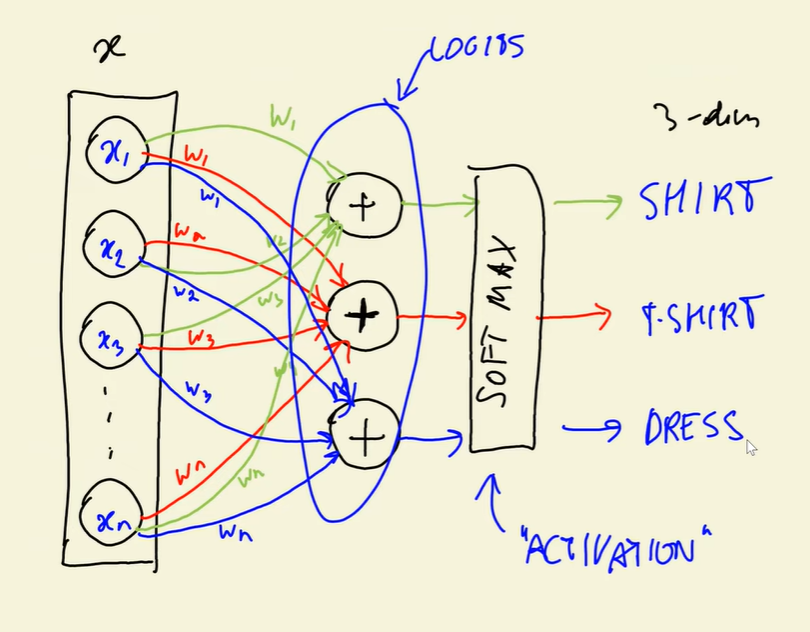

### Compile the model

Now we compile the model - something we need to do before training. We say which optimizer to use, which loss, and which metrics we're interested in monitoring - accuracy:

In [31]:
model.compile(optimizer=optimizer, loss=loss, metrics=['accuracy'])

### Training the model

In [32]:
history = model.fit(train_ds, epochs=10, validation_data=val_ds)

Epoch 1/10
68/96 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.6549 - loss: 1.3257

E0000 00:00:1795321782.258682   17014 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - accuracy: 0.6718 - loss: 1.2547

E0000 00:00:1795321795.994357   17016 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


96/96 ━━━━━━━━━━━━━━━━━━━━ 32s 259ms/step - accuracy: 0.6718 - loss: 1.2547 - val_accuracy: 0.7302 - val_loss: 1.3714
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 7s 67ms/step - accuracy: 0.8061 - loss: 0.6865 - val_accuracy: 0.7889 - val_loss: 0.8082
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 6s 59ms/step - accuracy: 0.8833 - loss: 0.3470 - val_accuracy: 0.7713 - val_loss: 0.9902
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - accuracy: 0.9195 - loss: 0.2237 - val_accuracy: 0.7889 - val_loss: 0.9513
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.9485 - loss: 0.1452 - val_accuracy: 0.8123 - val_loss: 0.8711
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 6s 57ms/step - accuracy: 0.9651 - loss: 0.1039 - val_accuracy: 0.8182 - val_loss: 0.8654
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 7s 74ms/step - accuracy: 0.9681 - loss: 0.0890 - val_accuracy: 0.7801 - val_loss: 0.9394
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 6s 67ms/step - accuracy: 0.9801 - loss: 0.0628 - val_accuracy: 0.7830 - val_loss: 

We pass the training dataset and say for how many epochs we want to run. One epoch is going over the dataset once. The dataset consists of batches of 32 images each (the last batch can be smaller). We train the model on one batch at a time - that's one iteration - and going over all batches once is one epoch. So 10 epochs means going over the data 10 times.

### Plotting accuracy

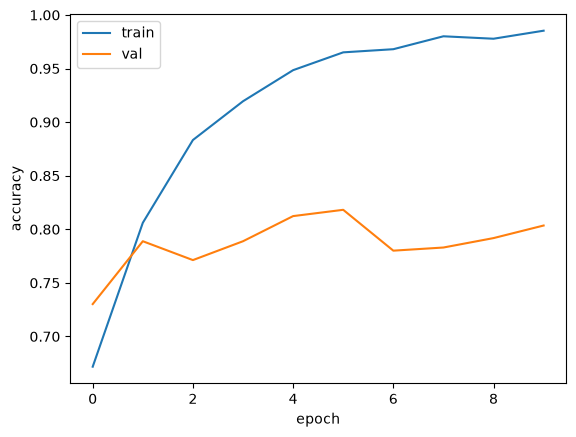

In [36]:
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend()
plt.show()